# Stage-rule sensors vs. the other sensors: correlation

**Question:** how strongly do the sensors that are *not* used to define the operating stages move together with the sensors that *are* used?

**Sensor sets** (from `excel_sensors/verdict.csv`, the Excel sensor check of 2026-10-15)
- Start: 255 Excel rows → drop not traceable (1), not usable (43), back-up twins (54) and duplicate rows (2) → **155 sensors**.
- `FIRC 1,2` (natural gas, read by the stage rules) was dropped as a twin of `FIRC 1,4`; it is put back here → **156 sensors**.
- **Stage sensors (50):** exactly the columns `operating_states.load_signals()` reads for the stage rules — 34 stack thermocouples, 5 string currents, EAPH heater power, stack-inlet air pressure, 2 air blowers, N2, H2, natural gas, 4 inlet thermocouples used as ambient proxy.
- **Other sensors (106):** the rest of the 156.

**Method**
- Data: `excel_sensors/x1min.parquet` (1-min means of all Excel tags, 39 days, 2025-10-30 → 2026-03-30) with the stage label per minute. `-1` (fill for unconnected channel) is blanked.
- Spearman rank correlation (handles on/off and non-linear but monotonic links), pairwise, at least 1 000 common minutes.
- Two views: **whole period** (all stages — dominated by heat-up / cool-down) and **hot operation** (stack ≥ 450 °C) where the slow temperature swing no longer links everything.
- The 50 stage sensors are also condensed into the **9 stage signals** the rules actually test (stack temperature = median of the 34 thermocouples, mean string current, …), so each other sensor gets one row of 9 numbers.

Outputs go to `03_data_analysis/stage_corr/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_rows", 200)

ROOT = Path.cwd()
if ROOT.name != "03_data_analysis":
    ROOT = ROOT / "03_data_analysis"
OUT = ROOT / "stage_corr"
OUT.mkdir(exist_ok=True)

verdict = pd.read_csv(ROOT / "excel_sensors" / "verdict.csv")
x = pd.read_parquet(ROOT / "excel_sensors" / "x1min.parquet")
print(
    f"{len(x):,} minutes, {x.shape[1]} columns, {x.index.min():%Y-%m-%d} → "
    f"{x.index.max():%Y-%m-%d}"
)

55,584 minutes, 254 columns, 2025-10-30 → 2026-03-30


## 1. The two sensor sets

In [2]:
DROP = ["Not traceable", "Not usable", "Back-up twin", "Duplicate row"]
keep = verdict[~verdict["verdict"].isin(DROP)].copy()
print("After removing not traceable / not usable / twins / duplicate rows:", len(keep))

firc12 = verdict[verdict["column"] == "ct_FIRC_12_PV_ProcessValue"]
keep = pd.concat([keep, firc12]).drop_duplicates("column").set_index("column")
print("With FIRC 1,2 (natural gas) put back:", len(keep))

# Stage-rule inputs, grouped by the signal the rule tests
# (operating_states.load_signals)
STAGE_SIGNALS = {
    "Stack temperature (median TIR 4,6,x)": [
        c for c in keep.index if c.startswith("TIR_4_6_")
    ],
    "String current (EIRC 4,s,2)": [
        f"PLC_hostSetp_ctrl_ctEIRC4{i}_rCurrMonitor" for i in range(1, 6)
    ],
    "Heater power (EIRC 2,01)": ["EIRC_2_01_ActV_In_ThreePhasePower"],
    "Air pressure stack inlet (PIR 2,02)": ["PIR_2_02"],
    "Air flow (FIRC 1,1,1 + 1,1,2)": [
        "ct_FIRC_111_PV_ProcessValue",
        "ct_FIRC_112_PV_ProcessValue",
    ],
    "N2 flow (FIRC 1,3)": ["ct_FIRC_13_PV_ProcessValue"],
    "H2 flow (FIRC 1,5)": ["ct_FIRC_15_PV_ProcessValue"],
    "Natural gas flow (FIRC 1,2)": ["ct_FIRC_12_PV_ProcessValue"],
    "Ambient proxy (median TIR 1,x inlets)": [
        "TIR_1_1_1",
        "TIR_1_2_1",
        "TIR_1_3",
        "TIR_1_4_1",
    ],
}
stage_cols = [c for cols in STAGE_SIGNALS.values() for c in cols]
missing = [c for c in stage_cols if c not in keep.index]
assert not missing, missing
other_cols = [c for c in keep.index if c not in stage_cols]
role = {c: r for r, cols in STAGE_SIGNALS.items() for c in cols}

print(f"Stage sensors: {len(stage_cols)}   Other sensors: {len(other_cols)}")
display(
    pd.Series({r: len(c) for r, c in STAGE_SIGNALS.items()}, name="sensors").to_frame()
)
display(
    keep.loc[other_cols]
    .groupby("area")
    .size()
    .sort_values(ascending=False)
    .rename("other sensors")
    .to_frame()
)

After removing not traceable / not usable / twins / duplicate rows: 155
With FIRC 1,2 (natural gas) put back: 156
Stage sensors: 50   Other sensors: 106


,sensors
"Stack temperature (median TIR 4,6,x)",34
"String current (EIRC 4,s,2)",5
"Heater power (EIRC 2,01)",1
"Air pressure stack inlet (PIR 2,02)",1
"Air flow (FIRC 1,1,1 + 1,1,2)",2
"N2 flow (FIRC 1,3)",1
"H2 flow (FIRC 1,5)",1
"Natural gas flow (FIRC 1,2)",1
"Ambient proxy (median TIR 1,x inlets)",4


,other sensors
area,
Stack electrical,47
Gas & air supply,14
Reformer / gas prep.,11
Off-gas & after-burner,9
Exhaust & heat recovery,7
Safety monitors,6
Air pre-heating,5
Anode recycle,3
Heater power,3


## 2. Clean data and build the 9 stage signals

`-1` is the logger's fill value for a channel without reading → blank. Stack thermocouples outside 0–1000 °C are blanked like in `operating_states.py`; the ambient proxy keeps only values below 60 °C.

In [3]:
cols = stage_cols + other_cols
d = x[cols].apply(pd.to_numeric, errors="coerce")
d = d.where(d != -1)
tc = STAGE_SIGNALS["Stack temperature (median TIR 4,6,x)"]
d[tc] = d[tc].where((d[tc] > 0) & (d[tc] < 1000))
amb = STAGE_SIGNALS["Ambient proxy (median TIR 1,x inlets)"]

sig = pd.DataFrame(
    {
        "Stack temperature": d[tc].median(axis=1),
        "String current": d[STAGE_SIGNALS["String current (EIRC 4,s,2)"]]
        .clip(lower=0)
        .mean(axis=1),
        "Heater power": d["EIRC_2_01_ActV_In_ThreePhasePower"],
        "Air pressure": d["PIR_2_02"],
        "Air flow": d[
            ["ct_FIRC_111_PV_ProcessValue", "ct_FIRC_112_PV_ProcessValue"]
        ].sum(axis=1, min_count=1),
        "N2 flow": d["ct_FIRC_13_PV_ProcessValue"],
        "H2 flow": d["ct_FIRC_15_PV_ProcessValue"],
        "Natural gas flow": d["ct_FIRC_12_PV_ProcessValue"],
        "Ambient proxy": d[amb].where(d[amb] < 60).median(axis=1),
    }
)
hot = sig["Stack temperature"] >= 450
print(
    f"Hot operation (stack ≥ 450 °C): {hot.sum():,} of {len(sig):,} "
    f"minutes ({hot.mean():.0%})"
)
display(sig.describe().T.round(2))

Hot operation (stack ≥ 450 °C): 26,414 of 55,584 minutes (48%)


,count,mean,std,min,25%,50%,75%,max
Stack temperature,54957.0,339.70,214.65,0.02,121.19,409.10,510.90,690.91
String current,55021.0,0.05,0.57,0.00,0.00,0.00,0.00,16.23
Heater power,55024.0,6643.99,7611.95,0.00,0.30,5576.40,10663.96,41413.64
Air pressure,54957.0,9.47,7.45,-0.98,3.41,11.64,12.58,33.34
Air flow,55024.0,5143.28,3017.08,0.00,5998.70,5999.90,6000.58,11244.96
N2 flow,55024.0,727.65,585.24,0.00,0.00,1199.79,1200.01,1206.97
H2 flow,55024.0,36.21,29.30,0.00,0.00,60.00,60.00,60.01
Natural gas flow,55024.0,3.03,33.74,0.00,0.00,0.00,0.00,615.59
Ambient proxy,54957.0,15.32,2.71,-0.77,14.46,16.13,17.04,23.86


## 3. Correlation function

Spearman = Pearson on ranks. Caution: sensors that sit at 0 most of the time (string currents, PLC voltage monitors — non-zero only in ~950 connected/load minutes) correlate mainly through *on together / off together*; a high r there means "switches with", not "tracks the value of".

Ranking once and using pairwise-complete minutes keeps it exact for gaps. Pairs with fewer than 1 000 common minutes, or where one side is constant, give NaN.

In [4]:
MIN_N = 1000


def spearman(a: pd.DataFrame, b: pd.DataFrame) -> pd.DataFrame:
    """Spearman r of every column of a against every column of b (pairwise complete)."""
    ra, rb = a.rank(), b.rank()
    out = pd.DataFrame(index=a.columns, columns=b.columns, dtype=float)
    for cb in b.columns:
        y = rb[cb]
        both = ra.notna() & y.notna().values[:, None]
        n = both.sum()
        # re-rank on the common rows so ties/gaps don't bias r
        for ca in a.columns:
            m = both[ca].values
            if n[ca] < MIN_N:
                continue
            u, v = a.loc[m, ca].rank(), b.loc[m, cb].rank()
            if u.std() == 0 or v.std() == 0:
                continue
            out.loc[ca, cb] = np.corrcoef(u, v)[0, 1]
    return out


def label(c):
    return keep.loc[c, "tag"] if c in keep.index else c

## 4. Other sensors vs. the 9 stage signals

One row per other sensor, one column per stage signal. This is the compact view: *which stage signal does each unused sensor follow?*

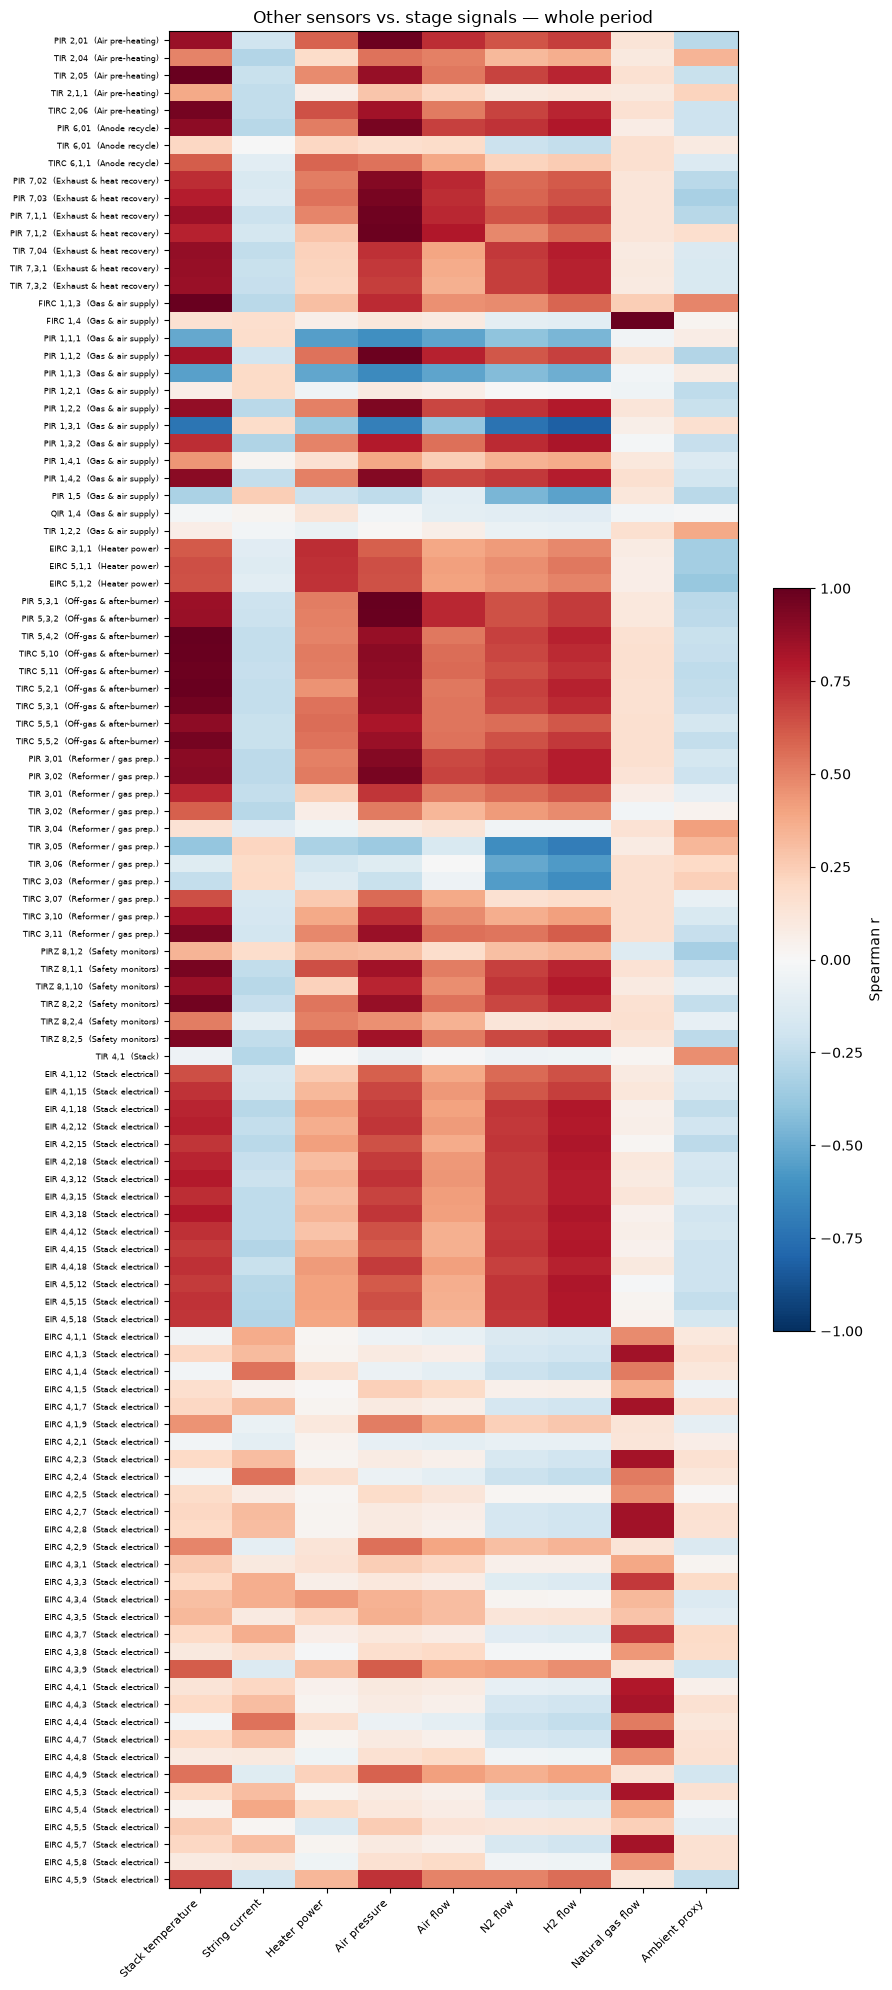

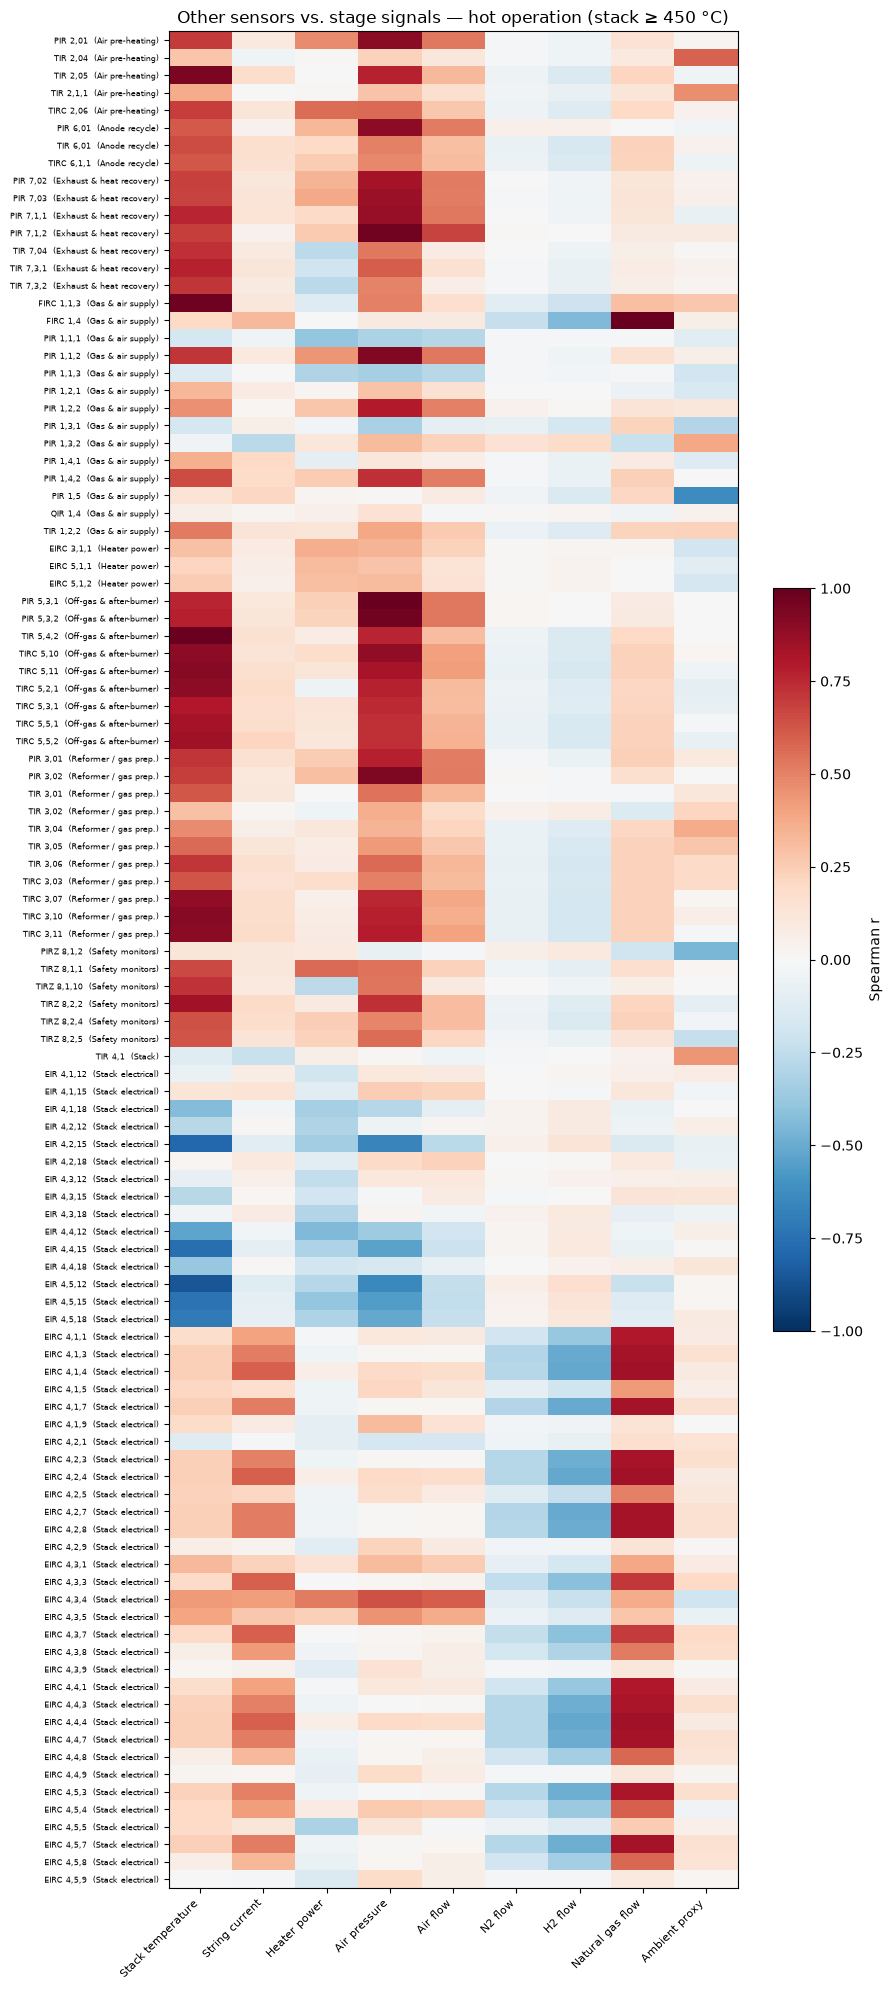

In [5]:
r_sig_all = spearman(d[other_cols], sig)
r_sig_hot = spearman(d.loc[hot, other_cols], sig[hot])
r_sig_all.index = r_sig_hot.index = [label(c) for c in other_cols]
r_sig_all.round(3).to_csv(OUT / "other_vs_stage_signals_all.csv")
r_sig_hot.round(3).to_csv(OUT / "other_vs_stage_signals_hot.csv")


def heat(r, title, path, figsize):
    order = (
        keep.loc[other_cols]
        .assign(t=[label(c) for c in other_cols])
        .sort_values(["area", "t"])
    )
    rows = [t for t in order["t"] if t in r.index]
    m = r.loc[rows]
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(
        m.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto"
    )
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(
        range(m.shape[0]),
        [f"{t}  ({order.set_index('t').loc[t, 'area']})" for t in rows],
        fontsize=6,
    )
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.4, label="Spearman r")
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()


heat(
    r_sig_all,
    "Other sensors vs. stage signals — whole period",
    OUT / "other_vs_stage_signals_all.png",
    (9, 20),
)
heat(
    r_sig_hot,
    "Other sensors vs. stage signals — hot operation (stack ≥ 450 °C)",
    OUT / "other_vs_stage_signals_hot.png",
    (9, 20),
)

## 5. Full matrix: 106 other sensors × 50 stage sensors

Same idea at sensor level. The 34 stack thermocouples form one block, so the stage-sensor axis is ordered by stage signal.

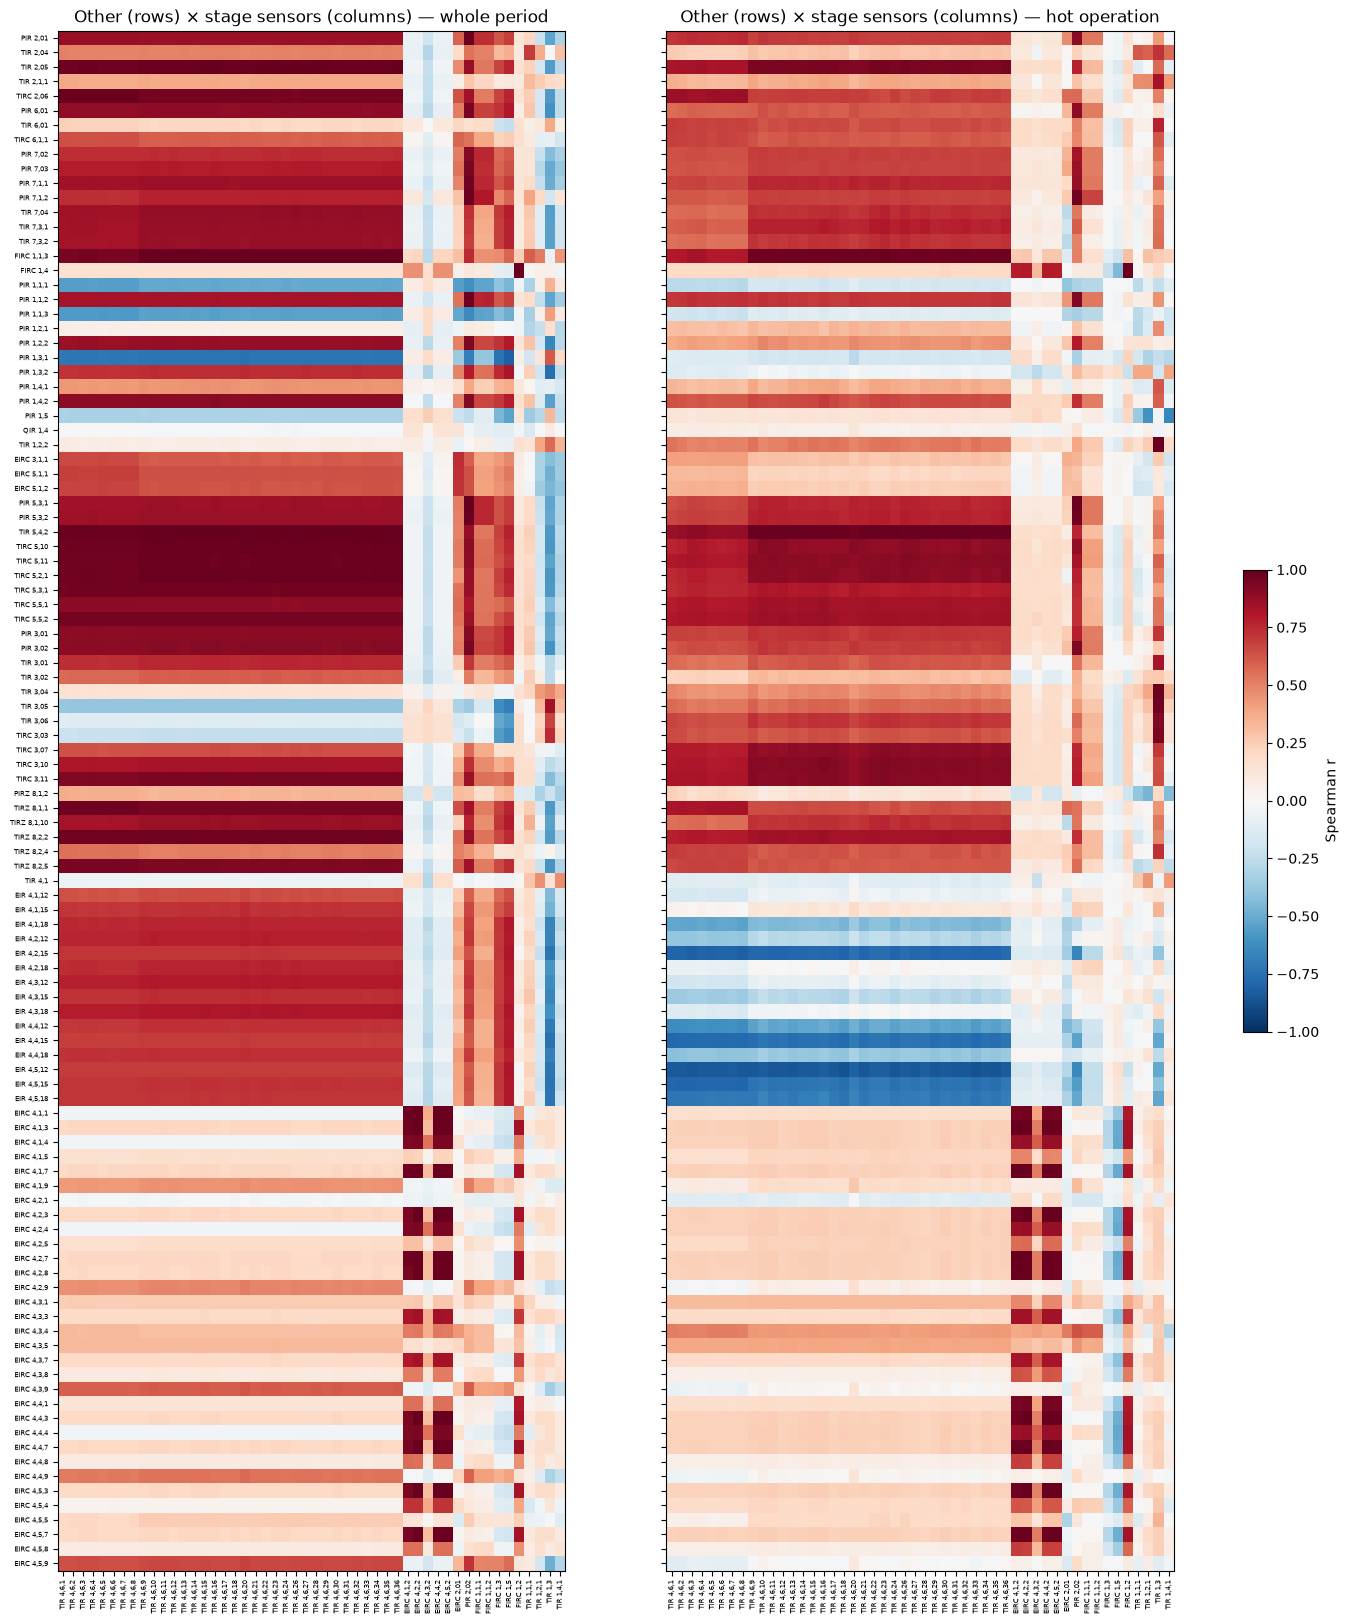

In [6]:
r_all = spearman(d[other_cols], d[stage_cols])
r_hot = spearman(d.loc[hot, other_cols], d.loc[hot, stage_cols])
for r in (r_all, r_hot):
    r.index = [label(c) for c in other_cols]
    r.columns = [label(c) for c in stage_cols]
r_all.round(3).to_csv(OUT / "other_vs_stage_sensors_all.csv")
r_hot.round(3).to_csv(OUT / "other_vs_stage_sensors_hot.csv")

fig, axes = plt.subplots(1, 2, figsize=(18, 20), sharey=True)
order = (
    keep.loc[other_cols]
    .assign(t=[label(c) for c in other_cols])
    .sort_values(["area", "t"])["t"]
)
for ax, r, t in [(axes[0], r_all, "whole period"), (axes[1], r_hot, "hot operation")]:
    m = r.loc[order]
    im = ax.imshow(
        m.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto"
    )
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=90, fontsize=5)
    ax.set_title(f"Other (rows) × stage sensors (columns) — {t}")
axes[0].set_yticks(range(len(order)), order, fontsize=5)
fig.colorbar(im, ax=axes, shrink=0.3, label="Spearman r")
fig.savefig(OUT / "other_vs_stage_sensors.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Best match per other sensor

For each other sensor: the stage sensor it follows most closely (largest |r|), in the whole period and in hot operation.

Classes (on the whole-period |r|):
- **Covered** |r| ≥ 0.9 — practically a copy of a stage sensor; adds little to stage detection.
- **Related** 0.7 ≤ |r| < 0.9 — follows a stage sensor but has its own part.
- **Independent** |r| < 0.7 — information the stage sensors do not carry.

`eta2_stage` (from the sensor check) is how much of the sensor's spread the stage label explains (0 = none, 1 = all). An *independent* sensor with high η² separates stages in a way the rules do not use yet.

In [7]:
def best(r):
    a = r.abs().astype(float)
    idx = a.fillna(-1).idxmax(axis=1).where(a.notna().any(axis=1))
    return pd.DataFrame(
        {
            "best_stage_sensor": idx,
            "r": [r.loc[i, c] if pd.notna(c) else np.nan for i, c in idx.items()],
        }
    )


ba = best(r_all)
bh = best(r_hot)
match = pd.DataFrame(
    {
        "tag": [label(c) for c in other_cols],
        "column": other_cols,
        "area": keep.loc[other_cols, "area"].values,
        "verdict": keep.loc[other_cols, "verdict"].values,
        "eta2_stage": keep.loc[other_cols, "eta2_stage"].values,
    }
).set_index("tag")
match["best_stage_sensor"] = ba["best_stage_sensor"]
match["best_role"] = match["best_stage_sensor"].map(
    {label(c): role[c] for c in stage_cols}
)
match["r_all"] = ba["r"].round(3)
match["best_stage_sensor_hot"] = bh["best_stage_sensor"]
match["r_hot"] = bh["r"].round(3)
a = match["r_all"].abs()
match["class"] = np.select(
    [a >= 0.9, a >= 0.7, a < 0.7], ["Covered", "Related", "Independent"], "No data"
)
match = match.sort_values(
    ["class", "r_all"], key=lambda s: s.abs() if s.name == "r_all" else s
)
match.to_csv(OUT / "best_match.csv")

print(match["class"].value_counts().to_string())
display(pd.crosstab(match["area"], match["class"], margins=True))

class
Covered        41
Independent    33
Related        32


class,Covered,Independent,Related,All
area,,,,
Air pre-heating,3,2,0,5
Anode recycle,1,2,0,3
Exhaust & heat recovery,4,0,3,7
Gas & air supply,5,7,2,14
Heater power,0,0,3,3
Off-gas & after-burner,9,0,0,9
Reformer / gas prep.,3,4,4,11
Safety monitors,3,2,1,6
Stack,0,1,0,1


In [8]:
display(match.drop(columns=["column"]).sort_values(["class", "area"]))

,area,verdict,eta2_stage,best_stage_sensor,best_role,r_all,best_stage_sensor_hot,r_hot,class
tag,,,,,,,,,
"PIR 2,01",Air pre-heating,Useful,0.448,"PIR 2,02","Air pressure stack inlet (PIR 2,02)",0.981,"PIR 2,02",0.903,Covered
"TIRC 2,06",Air pre-heating,Key,0.659,"TIR 4,6,5","Stack temperature (median TIR 4,6,x)",0.982,"TIR 4,6,5",0.862,Covered
"TIR 2,05",Air pre-heating,Key,0.597,"TIR 4,6,23","Stack temperature (median TIR 4,6,x)",0.993,"TIR 4,6,23",0.960,Covered
"PIR 6,01",Anode recycle,Key,0.501,"PIR 2,02","Air pressure stack inlet (PIR 2,02)",0.951,"PIR 2,02",0.895,Covered
"PIR 7,02",Exhaust & heat recovery,Useful,0.239,"PIR 2,02","Air pressure stack inlet (PIR 2,02)",0.916,"PIR 2,02",0.832,Covered
"PIR 7,03",Exhaust & heat recovery,Useful,0.326,"PIR 2,02","Air pressure stack inlet (PIR 2,02)",0.946,"PIR 2,02",0.860,Covered
"PIR 7,1,1",Exhaust & heat recovery,Useful,0.420,"PIR 2,02","Air pressure stack inlet (PIR 2,02)",0.977,"PIR 2,02",0.874,Covered
"PIR 7,1,2",Exhaust & heat recovery,Limited,0.256,"PIR 2,02","Air pressure stack inlet (PIR 2,02)",0.977,"PIR 2,02",0.961,Covered
"PIR 1,4,2",Gas & air supply,Key,0.675,"PIR 2,02","Air pressure stack inlet (PIR 2,02)",0.922,"PIR 2,02",0.734,Covered


## 7. Which stage signal explains the other sensors?

Count of other sensors whose best match (whole period / hot) is in each stage signal group.

,whole period,hot operation
"Stack temperature (median TIR 4,6,x)",33,34
"Air pressure stack inlet (PIR 2,02)",20,24
"String current (EIRC 4,s,2)",20,24
"H2 flow (FIRC 1,5)",14,0
"Ambient proxy (median TIR 1,x inlets)",10,18
"Natural gas flow (FIRC 1,2)",6,1
"Heater power (EIRC 2,01)",3,4
"Air flow (FIRC 1,1,1 + 1,1,2)",0,1


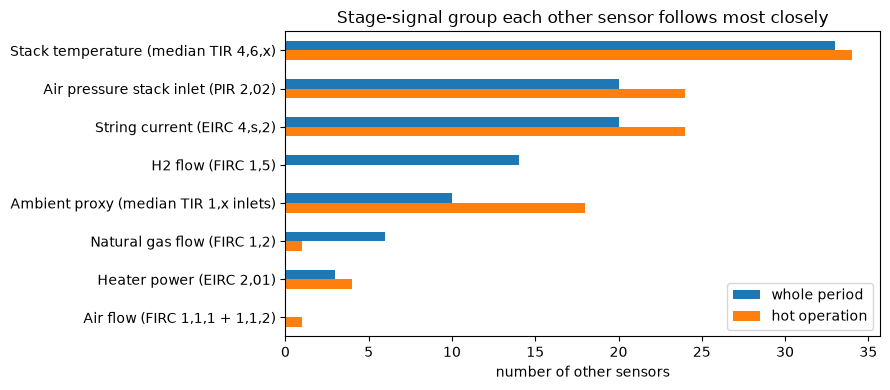

In [9]:
cnt = (
    pd.DataFrame(
        {
            "whole period": match["best_role"].value_counts(),
            "hot operation": match["best_stage_sensor_hot"]
            .map({label(c): role[c] for c in stage_cols})
            .value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
    .sort_values("whole period", ascending=False)
)
display(cnt)

fig, ax = plt.subplots(figsize=(9, 4))
cnt.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_xlabel("number of other sensors")
ax.set_title("Stage-signal group each other sensor follows most closely")
fig.tight_layout()
fig.savefig(OUT / "best_role_counts.png", dpi=130)
plt.show()

## 8. Whole period vs. hot operation

In the whole period most sensors ride on the same slow heat-up / cool-down swing, so high r is partly "both are hot when the plant is hot". In hot operation that swing is gone; a link that survives there is a real process link.

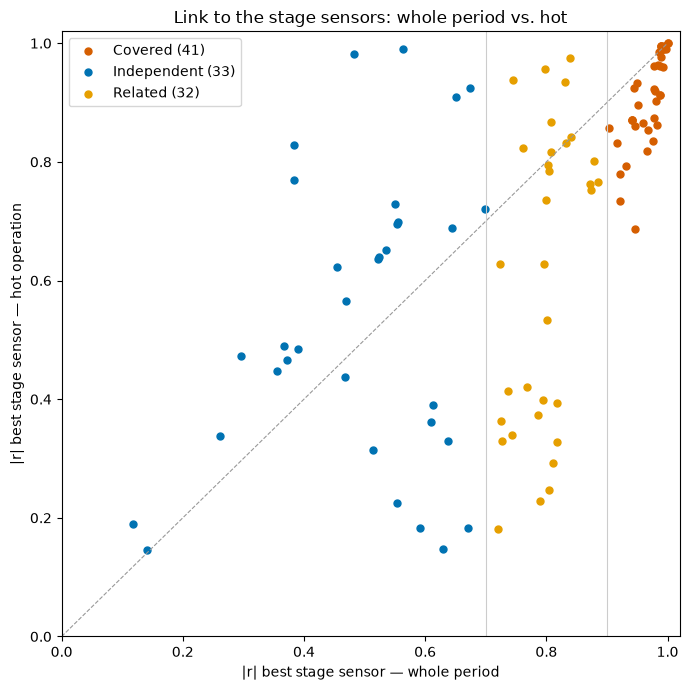

1 sensors look covered over the whole period but are NOT covered in hot operation:


,area,best_stage_sensor,r_all,best_stage_sensor_hot,r_hot
tag,,,,,
"TIRZ 8,2,5",Safety monitors,"TIR 4,6,8",0.947,"TIR 4,6,8",0.686


In [10]:
fig, ax = plt.subplots(figsize=(7, 7))
colors = {
    "Covered": "#D55E00",
    "Related": "#E69F00",
    "Independent": "#0072B2",
    "No data": "#999999",
}
for k, g in match.groupby("class"):
    ax.scatter(
        g["r_all"].abs(),
        g["r_hot"].abs(),
        s=25,
        color=colors[k],
        label=f"{k} ({len(g)})",
    )
ax.plot([0, 1], [0, 1], color="#999", lw=0.8, ls="--")
ax.axvline(0.9, color="#ccc", lw=0.8)
ax.axvline(0.7, color="#ccc", lw=0.8)
ax.set_xlabel("|r| best stage sensor — whole period")
ax.set_ylabel("|r| best stage sensor — hot operation")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend()
ax.set_title("Link to the stage sensors: whole period vs. hot")
for t, rr in match[
    (match["class"] == "Covered") & (match["r_hot"].abs() < 0.5)
].iterrows():
    ax.annotate(t, (abs(rr["r_all"]), abs(rr["r_hot"])), fontsize=6)
fig.tight_layout()
fig.savefig(OUT / "all_vs_hot.png", dpi=130)
plt.show()

lost = match[(match["r_all"].abs() >= 0.9) & (match["r_hot"].abs() < 0.7)]
print(
    f"{len(lost)} sensors look covered over the whole period but are NOT "
    "covered in hot operation:"
)
display(lost[["area", "best_stage_sensor", "r_all", "best_stage_sensor_hot", "r_hot"]])

## 9. Independent sensors that still separate the stages

Candidates that could strengthen or check the stage rules: low link to every stage sensor but a clear stage pattern (η² ≥ 0.3).

,area,verdict,eta2_stage,best_stage_sensor,r_all,r_hot
tag,,,,,,
"EIRC 4,2,1",Stack electrical,Key,0.846,"FIRC 1,2",0.118,0.189
"EIRC 4,3,1",Stack electrical,Key,0.821,"FIRC 1,2",0.390,0.484
"EIRC 4,3,4",Stack electrical,Limited,0.555,"EIRC 4,2,2",0.524,0.639
"TIRC 6,1,1",Anode recycle,Key,0.519,"TIR 4,6,1",0.645,0.688
"TIRZ 8,2,4",Safety monitors,Useful,0.465,"TIR 4,6,1",0.550,0.729
"TIR 6,01",Anode recycle,Useful,0.410,"TIR 1,3",0.383,0.770
"TIRC 3,07",Reformer / gas prep.,Useful,0.402,"TIR 4,6,23",0.651,0.909
"EIRC 4,4,8",Stack electrical,Limited,0.355,"EIRC 4,1,2",0.555,0.698
"EIRC 4,5,8",Stack electrical,Limited,0.355,"EIRC 4,1,2",0.554,0.696


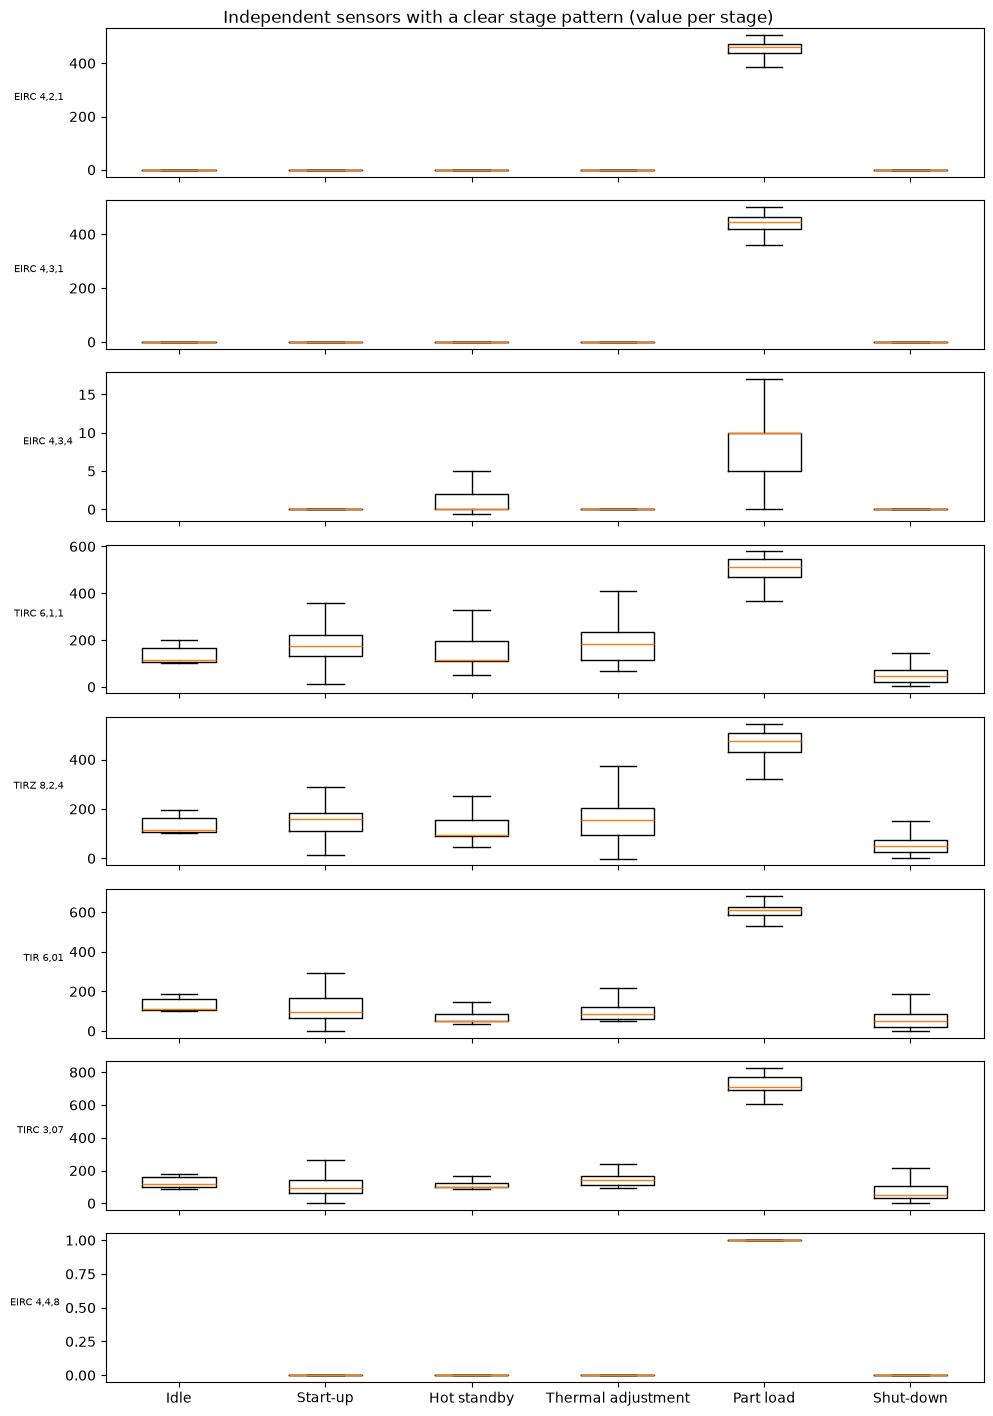

In [11]:
cand = match[
    (match["class"] == "Independent") & (match["eta2_stage"] >= 0.3)
].sort_values("eta2_stage", ascending=False)
display(cand[["area", "verdict", "eta2_stage", "best_stage_sensor", "r_all", "r_hot"]])

STAGES = [
    "Idle",
    "Start-up",
    "Hot standby",
    "Thermal adjustment",
    "Part load",
    "Shut-down",
]
show = cand.head(8)
if len(show):
    fig, axes = plt.subplots(len(show), 1, figsize=(10, 1.8 * len(show)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (t, rr) in zip(axes, show.iterrows()):
        data = [d.loc[x["stage"] == s, rr["column"]].dropna() for s in STAGES]
        ax.boxplot(data, showfliers=False)
        ax.set_ylabel(t, fontsize=7, rotation=0, ha="right")
    axes[-1].set_xticks(range(1, len(STAGES) + 1), STAGES)
    fig.suptitle("Independent sensors with a clear stage pattern (value per stage)")
    fig.tight_layout()
    fig.savefig(OUT / "independent_candidates.png", dpi=130)
    plt.show()

## 10. Summary

In [12]:
n = match["class"].value_counts()
print(
    f"Stage sensors: {len(stage_cols)} (9 stage signals).  Other "
    f"sensors: {len(other_cols)}."
)
for k in ["Covered", "Related", "Independent", "No data"]:
    if k in n:
        print(f"  {k:12s} {n[k]:3d}")
print(f"Covered over the whole period but not in hot operation: {len(lost)}")
print(f"Independent with clear stage pattern (η² ≥ 0.3): {len(cand)}")
print("\nMost common best stage signal (whole period):")
print(cnt["whole period"].head(5).to_string())
print(f"\nFiles in {OUT}:")
for p in sorted(OUT.iterdir()):
    print("  ", p.name)

Stage sensors: 50 (9 stage signals).  Other sensors: 106.
  Covered       41
  Related       32
  Independent   33
Covered over the whole period but not in hot operation: 1
Independent with clear stage pattern (η² ≥ 0.3): 11

Most common best stage signal (whole period):
Stack temperature (median TIR 4,6,x)     33
Air pressure stack inlet (PIR 2,02)      20
String current (EIRC 4,s,2)              20
H2 flow (FIRC 1,5)                       14
Ambient proxy (median TIR 1,x inlets)    10

Files in c:\Users\mrgur\Guru_prasaath\06_Projects\01_POC\03_data_analysis\stage_corr:
   all_vs_hot.png
   best_match.csv
   best_role_counts.png
   independent_candidates.png
   other_vs_stage_sensors.png
   other_vs_stage_sensors_all.csv
   other_vs_stage_sensors_hot.csv
   other_vs_stage_signals_all.csv
   other_vs_stage_signals_all.png
   other_vs_stage_signals_hot.csv
   other_vs_stage_signals_hot.png
